In [1]:
# Import packages and setup gpu configuration.
# This code block shouldnt need to be adjusted!
import os
import sys
import json
import yaml
import numpy as np
import copy
import math
import time
import random
import matplotlib.pyplot as plt
import h5py

import torch
import torch.nn as nn
from torchvision import transforms
import utils

# tf32 data type is faster than standard float32
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.benchmark = True # fixes Conv3D if used

### Multi-GPU config ###
device_count = torch.cuda.device_count()
print(f"Number of available CUDA devices: {device_count}")

local_rank = os.getenv('LOCAL_RANK')
local_rank = 0 if local_rank is None else int(local_rank)
print(f"LOCAL RANK={local_rank}")

num_devices = os.getenv('NUM_GPUS')
num_devices = 1 if num_devices is None else int(num_devices)
print(f"NUM GPUS={num_devices}")
distributed = True if num_devices>1 else False
if distributed: assert device_count==num_devices

node = os.getenv('SLURM_NODEID')
node = 0 if node is None else int(node)
print(f"NODE={node}")

global_rank = os.getenv('RANK')
global_rank = 0 if global_rank is None else int(global_rank)
print(f"GLOBAL RANK={global_rank}")

world_size = os.getenv('WORLD_SIZE')
world_size = 1 if world_size is None else int(world_size)
print(f"WORLD_SIZE={world_size}")

if utils.is_interactive():
    # Following allows you to change functions in utils.py and 
    # have this notebook automatically update with your revisions
    %load_ext autoreload
    %autoreload 2
    from tqdm.notebook import tqdm
else:
    from tqdm import tqdm

# Load parameters from yaml config
config = yaml.load(open('config.yaml', 'r'), Loader=yaml.FullLoader)

# create global variables from the config
print("\n__CONFIG__")
for attribute_name in config.keys():
    print(f"{attribute_name} = {config[attribute_name]}")
    globals()[attribute_name] = config[f'{attribute_name}']
print("\n")

data_type = torch.float32 # change depending on your mixed_precision
global_batch_size = batch_size * world_size
device = torch.device('cuda')
print("device =", device, "distributed =",distributed, "num_devices =", num_devices, "local rank =", local_rank, "world size =", world_size, "data_type =", data_type)

# seed all random functions
utils.seed_everything(seed + global_rank)

Number of available CUDA devices: 1
LOCAL RANK=0
NUM GPUS=1
NODE=0
GLOBAL RANK=0
WORLD_SIZE=1

__CONFIG__
model_name = usebrainTrue
data_path = /weka/proj-medarc/shared/mindeyev2_dataset
batch_size = 128
wandb_log = True
ckpt_interval = 10
ckpt_saving = False
seed = 0
max_lr = 3e-05
num_epochs = 25
use_brain = True
temperature = 0.006


device = cuda distributed = False num_devices = 1 local rank = 0 world size = 1 data_type = torch.float32


# Prep data, models, and dataloaders

### Load all voxels for given NSD subject

In [2]:
subject_id = 1
f = h5py.File(f'{data_path}/betas_all_subj0{subject_id}_fp32_renorm.hdf5', 'r')
voxels = f['betas'][:] # preloading all voxels for given subject
print("voxels", voxels.shape)

voxels (30000, 15724)


### Load Images

In [3]:
f = h5py.File(f'{data_path}/coco_images_224_float16.hdf5', 'r')
images = f['images'][:] # preloading all images for easy indexing
print("images", images.shape)

images (73000, 3, 224, 224)


### Load Captions

In [4]:
# load image captions
annots = np.load(f'{data_path}/COCO_73k_annots_curated.npy')
print("annots", annots.shape)

annots (73000, 5)


### Pair Captions & Images with voxels

images_train torch.Size([27000, 3, 224, 224])
images_test torch.Size([3000, 3, 224, 224])
annots_train (27000, 5)
annots_test (3000, 5)


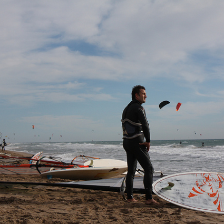

['' 'A man standing on the beach beside surf boards' ''
 'a man is flying a kite over a beach' '']


In [5]:
shared1000 = np.load(f"{data_path}/shared1000.npy")

# image train/test split
file_path = f"{data_path}/COCO_73k_subj_indices.hdf5"
with h5py.File(file_path, 'r') as f: # keys : from subj01 to 08
    data = {key: f[key][()] for key in f.keys()}

image_indices = data["subj01"]   #[30000,] global indices
is_shared = shared1000[image_indices]

image_indices_train = image_indices[~is_shared]
image_indices_test = image_indices[is_shared]

# split images
images_train = torch.tensor(images[image_indices_train]).float() # (27000, 3, 224, 224)
images_test = torch.tensor(images[image_indices_test]).float() # (3000, 3, 224, 224)

print("images_train", images_train.shape)
print("images_test", images_test.shape)

# split voxels
shared_voxel_indices = shared1000[data["subj01"]]
voxels_train = torch.tensor(voxels[~shared_voxel_indices]) # (27000, 15724)
voxels_test = torch.tensor(voxels[shared_voxel_indices]) # (3000, 15724)

#split annots
annots_train = annots[image_indices_train]
annots_test = annots[image_indices_test]
print("annots_train", annots_train.shape)
print("annots_test", annots_test.shape)

# check whether the annotations pairs with image order
display(utils.torch_to_Image(images_train[0]))
print(annots_train[0])

In [15]:
# print(len(annots_train[0]),annots_train[0])
longest_sentences = np.array([max(row, key=len) for row in annots])
print(longest_sentences.shape)
np.save( "/weka/proj-fmri/tong/annots_73k.npy",longest_sentences)

(73000,)


### Check blank captions

In [25]:
utils.check_blank(annots_train)

No.0 Image Got 3 blank captions.
No.1 Image Got 2 blank captions.
No.2 Image Got 4 blank captions.
No.3 Image Got 1 blank captions.
No.4 Image Got 4 blank captions.
No.5 Image Got 3 blank captions.
No.6 Image Got 2 blank captions.
No.7 Image Got 1 blank captions.
No.8 Image Got 3 blank captions.
No.9 Image Got 4 blank captions.
No.10 Image Got 4 blank captions.
No.11 Image Got 2 blank captions.
No.12 Image Got 3 blank captions.
No.13 Image Got 4 blank captions.
No.14 Image Got 4 blank captions.
No.15 Image Got 4 blank captions.
No.16 Image Got 3 blank captions.
No.17 Image Got 3 blank captions.
No.18 Image Got 4 blank captions.
No.19 Image Got 3 blank captions.
No.20 Image Got 4 blank captions.
No.21 Image Got 4 blank captions.
No.22 Image Got 4 blank captions.
No.23 Image Got 1 blank captions.
No.24 Image Got 4 blank captions.
No.25 Image Got 4 blank captions.
No.26 Image Got 4 blank captions.
No.27 Image Got 3 blank captions.
No.28 Image Got 3 blank captions.
No.29 Image Got 4 blank 

95052